Loading orders.csv ...
Raw shape: (25000, 28)
Columns: ['order_id', 'customer_id', 'order_date', 'year', 'month', 'quarter', 'day_of_week', 'product_name', 'category', 'unit_price_usd', 'quantity', 'subtotal_usd', 'discount_pct', 'discount_amount_usd', 'shipping_fee_usd', 'tax_pct', 'tax_amount_usd', 'total_amount_usd', 'payment_method', 'device_used', 'delivery_days', 'delivery_date', 'order_status', 'returned', 'customer_rating', 'session_duration_minutes', 'pages_viewed_before_purchase', 'is_repeat_customer']

Using → customer='customer_id'  date='order_date'  amount='total_amount_usd'  order_id='order_id'
Cleaning: 25000 → 21524 rows after drops.
Snapshot date for Recency: 2026-03-31

RFM shape: (7474, 4)
       Recency  Frequency  Monetary
count  7474.00    7474.00   7474.00
mean    682.93       2.88    361.96
std     561.13       1.53    314.48
min       1.00       1.00      8.61
25%     224.00       2.00    140.17
50%     534.00       3.00    277.88
75%    1028.00       4.00    

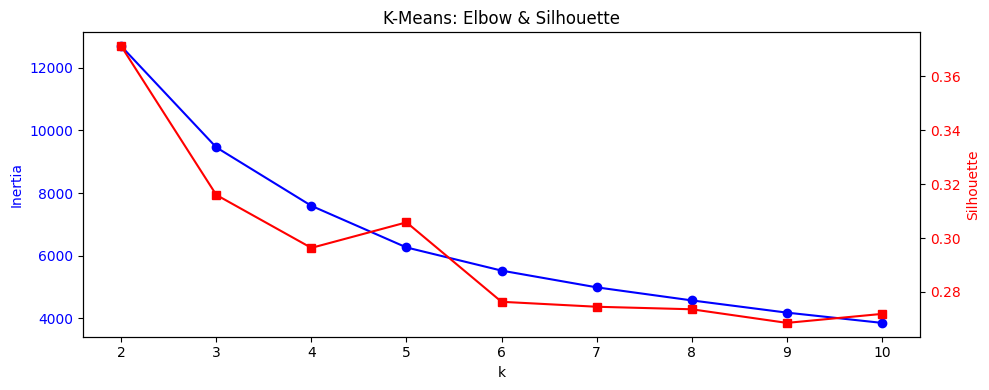


Optimal k = 2  (silhouette = 0.3711)
DBSCAN flagged 2 noise points (0.0%).


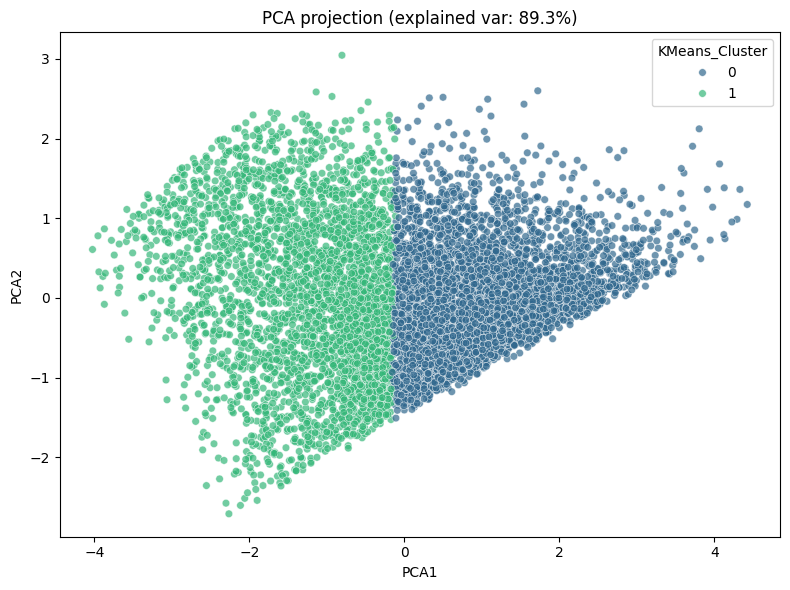

t-SNE: subsampled 5000 of 7474.


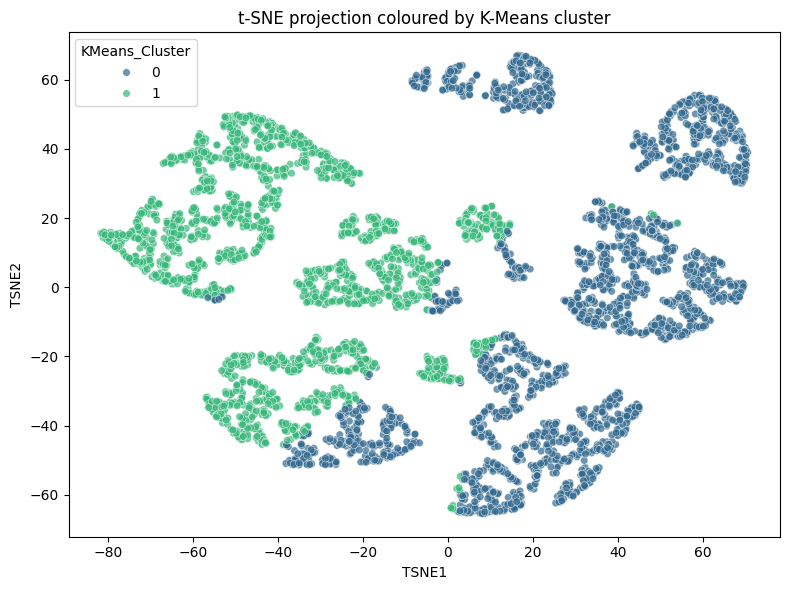


=== Marketing Personas ===
 KMeans_Cluster  Size  Avg_Recency  Avg_Frequency  Avg_Monetary  Total_Revenue  Pct_Customers  Pct_Revenue
              0  4181       398.18           3.83        522.39     2184101.35           0.56         0.81
              1  3293      1044.46           1.67        158.27      521184.03           0.44         0.19

=== Persona Interpretation ===

Cluster 0  →  Regular / Core
  Size: 4181 (55.9% of customers, 80.7% of revenue)
  Avg Recency: 398 d | Avg Frequency: 3.8 orders | Avg Monetary: $522.39
  → Action: Mid RFM. Cross-sell, seasonal offers, steady engagement.

Cluster 1  →  Dormant / At Risk
  Size: 3293 (44.1% of customers, 19.3% of revenue)
  Avg Recency: 1044 d | Avg Frequency: 1.7 orders | Avg Monetary: $158.27
  → Action: Old, infrequent, low value. Win-back or suppress.

Saved: personas.csv, customers_with_segments.csv


In [ ]:
"""
Case Study 3: E-Commerce Customer Segmentation — orders.csv
===========================================================
Library-first: pandas (I/O + RFM), sklearn (scaling, K-Means, DBSCAN,
PCA, t-SNE, silhouette), numpy (log1p / argmax), seaborn (plots).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

# ==================================================================
# 0. CONFIG  ── tuned for the shipped orders.csv ───────────────────
# ==================================================================
ORDERS_PATH = "orders.csv"
RANDOM_STATE = 42

# These are the actual column names in your file.
# Auto-detection below also recognises them, but explicit is safest.
MANUAL_CUSTOMER_COL = "customer_id"
MANUAL_DATE_COL     = "order_date"
MANUAL_AMOUNT_COL   = "total_amount_usd"     # ← the money column
MANUAL_ORDER_ID_COL = "order_id"             # ← for correct Frequency
MANUAL_QTY_COL      = None                   # not needed (amount is enough)
MANUAL_PRICE_COL    = None

TSNE_MAX_SAMPLES = 5000
DBSCAN_EPS       = 0.8
DBSCAN_MIN_PTS   = 10

# ==================================================================
# 1. LOAD
# ==================================================================
print("Loading", ORDERS_PATH, "...")
df = pd.read_csv(ORDERS_PATH)
print(f"Raw shape: {df.shape}")
print("Columns:", list(df.columns))

# ==================================================================
# 2. COLUMN RESOLUTION
# ==================================================================
def resolve_column(df, candidates, label, required=True):
    for cand in candidates:
        if cand in df.columns:
            return cand
    lower_map = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    if required:
        raise ValueError(f"Missing {label} column. Tried {candidates}. "
                         f"Available: {list(df.columns)}")
    return None

customer_col = MANUAL_CUSTOMER_COL or resolve_column(
    df, ["customer_id", "CustomerID", "user_id", "Customer"], "customer ID")

date_col = MANUAL_DATE_COL or resolve_column(
    df, ["order_date", "InvoiceDate", "OrderDate", "PurchaseDate", "date"],
    "order date")

amount_col = MANUAL_AMOUNT_COL or resolve_column(
    df, ["total_amount_usd", "subtotal_usd", "TotalAmount", "Amount",
         "Revenue", "LineTotal", "OrderTotal"], "amount", required=False)

order_id_col = MANUAL_ORDER_ID_COL or resolve_column(
    df, ["order_id", "OrderID", "InvoiceNo", "invoice_no"], "order ID",
    required=False)

qty_col   = MANUAL_QTY_COL or resolve_column(
    df, ["quantity", "Quantity", "qty", "units"], "quantity", required=False)
price_col = MANUAL_PRICE_COL or resolve_column(
    df, ["unit_price_usd", "unit_price", "UnitPrice", "price"],
    "unit price", required=False)

if amount_col is None and not (qty_col and price_col):
    raise ValueError("No amount column AND no (qty × price) pair found.")

print(f"\nUsing → customer='{customer_col}'  date='{date_col}'  "
      f"amount='{amount_col}'  order_id='{order_id_col}'")

# ==================================================================
# 3. CLEANING
# ==================================================================
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
before = len(df)
df = df.dropna(subset=[customer_col, date_col])

# Drop cancelled / returned-to-sender orders (if the column exists)
if "order_status" in df.columns:
    cancel_mask = df["order_status"].astype(str).str.lower().isin(
        ["cancelled", "canceled", "returned"])
    df = df[~cancel_mask]

# Build line_total: prefer the amount column, else qty × price
if amount_col is not None:
    df["line_total"] = pd.to_numeric(df[amount_col], errors="coerce")
else:
    df["line_total"] = (pd.to_numeric(df[qty_col],   errors="coerce")
                      * pd.to_numeric(df[price_col], errors="coerce"))

df = df.dropna(subset=["line_total"])

if qty_col is not None and qty_col in df.columns:
    df = df[pd.to_numeric(df[qty_col], errors="coerce").fillna(1) > 0]

df = df[df["line_total"] > 0]
print(f"Cleaning: {before} → {len(df)} rows after drops.")

# ==================================================================
# 4. RFM AGGREGATION  (line-item aware)
# ==================================================================
snapshot_date = df[date_col].max() + pd.Timedelta(days=1)
print(f"Snapshot date for Recency: {snapshot_date.date()}")

# Frequency = number of unique orders, not unique days.
if order_id_col is not None:
    freq_spec = (order_id_col, "nunique")
else:
    freq_spec = (date_col, "nunique")   # fallback

rfm = (
    df.groupby(customer_col)
      .agg(
          Recency  =(date_col,     lambda s: (snapshot_date - s.max()).days),
          Frequency=freq_spec,
          Monetary =("line_total", "sum"),
      )
      .reset_index()
      .rename(columns={customer_col: "CustomerID"})
)
print(f"\nRFM shape: {rfm.shape}")
print(rfm.describe().round(2))

# ==================================================================
# 5. PREPROCESS + SCALE
# ==================================================================
rfm["Monetary_log"] = np.log1p(rfm["Monetary"])
features = ["Recency", "Frequency", "Monetary_log"]

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(rfm[features])

# ==================================================================
# 6. K-MEANS — elbow + silhouette
# ==================================================================
inertia, sil_scores = [], []
K_range = list(range(2, 11))

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(K_range, inertia, "bo-")
ax1.set_xlabel("k"); ax1.set_ylabel("Inertia", color="b")
ax1.tick_params(axis="y", labelcolor="b")
ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, "rs-")
ax2.set_ylabel("Silhouette", color="r")
ax2.tick_params(axis="y", labelcolor="r")
plt.title("K-Means: Elbow & Silhouette")
fig.tight_layout(); plt.show()

optimal_k = K_range[int(np.argmax(sil_scores))]
print(f"\nOptimal k = {optimal_k}  (silhouette = {max(sil_scores):.4f})")

rfm["KMeans_Cluster"] = KMeans(
    n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10
).fit_predict(X_scaled)

# ==================================================================
# 7. DBSCAN
# ==================================================================
rfm["DBSCAN_Cluster"] = DBSCAN(
    eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_PTS
).fit_predict(X_scaled)

n_noise = int((rfm["DBSCAN_Cluster"] == -1).sum())
print(f"DBSCAN flagged {n_noise} noise points ({n_noise/len(rfm):.1%}).")

# ==================================================================
# 8. PCA
# ==================================================================
pca   = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
rfm["PCA1"], rfm["PCA2"] = X_pca[:, 0], X_pca[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=rfm, x="PCA1", y="PCA2", hue="KMeans_Cluster",
                palette="viridis", alpha=0.7, s=30)
plt.title(f"PCA projection (explained var: {pca.explained_variance_ratio_.sum():.1%})")
plt.tight_layout(); plt.show()

# ==================================================================
# 9. t-SNE
# ==================================================================
if len(X_scaled) > TSNE_MAX_SAMPLES:
    idx = np.random.RandomState(RANDOM_STATE).choice(
        len(X_scaled), TSNE_MAX_SAMPLES, replace=False)
    X_tsne_in = X_scaled[idx]
    rfm_tsne  = rfm.iloc[idx].copy()
    print(f"t-SNE: subsampled {TSNE_MAX_SAMPLES} of {len(X_scaled)}.")
else:
    X_tsne_in = X_scaled
    rfm_tsne  = rfm.copy()

perplexity = min(30, max(5, len(X_tsne_in) // 100))
tsne   = TSNE(n_components=2, perplexity=perplexity,
              random_state=RANDOM_STATE, init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_tsne_in)
rfm_tsne["TSNE1"], rfm_tsne["TSNE2"] = X_tsne[:, 0], X_tsne[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=rfm_tsne, x="TSNE1", y="TSNE2", hue="KMeans_Cluster",
                palette="viridis", alpha=0.7, s=30)
plt.title("t-SNE projection coloured by K-Means cluster")
plt.tight_layout(); plt.show()

# ==================================================================
# 10. PERSONAS
# ==================================================================
personas = (
    rfm.groupby("KMeans_Cluster")
       .agg(Size          =("CustomerID", "count"),
            Avg_Recency   =("Recency",    "mean"),
            Avg_Frequency =("Frequency",  "mean"),
            Avg_Monetary  =("Monetary",   "mean"),
            Total_Revenue =("Monetary",   "sum"))
       .reset_index()
       .sort_values("Avg_Monetary", ascending=False)
)
personas["Pct_Customers"] = personas["Size"] / personas["Size"].sum()
personas["Pct_Revenue"]   = personas["Total_Revenue"] / personas["Total_Revenue"].sum()

print("\n=== Marketing Personas ===")
print(personas.round(2).to_string(index=False))

def label_persona(row, overall_freq, overall_mon):
    r, f, m = row["Avg_Recency"], row["Avg_Frequency"], row["Avg_Monetary"]
    if r < 60 and f >= overall_freq * 1.5 and m >= overall_mon * 1.5:
        return "VIP / Champions", ("Recent, frequent, high-spend. Concierge, "
            "early access, loyalty tier.")
    if r < 90 and f >= overall_freq:
        return "Loyal Customers", ("Recent & frequent. Rewards, referrals, "
            "upsell premium lines.")
    if r < 90 and f < overall_freq:
        return "New / Promising", ("Recent, low frequency. Onboarding, "
            "2nd-purchase discount, nurture content.")
    if r >= 180 and f < overall_freq:
        return "Dormant / At Risk", ("Old, infrequent, low value. Win-back "
            "or suppress.")
    if m >= overall_mon * 1.5:
        return "Big Spenders (occasional)", ("High spend, low frequency. "
            "Personalised bundles, limited editions.")
    return "Regular / Core", ("Mid RFM. Cross-sell, seasonal offers, "
        "steady engagement.")

overall_freq = rfm["Frequency"].mean()
overall_mon  = rfm["Monetary"].mean()

print("\n=== Persona Interpretation ===")
for _, row in personas.iterrows():
    name, action = label_persona(row, overall_freq, overall_mon)
    print(f"\nCluster {int(row['KMeans_Cluster'])}  →  {name}\n"
          f"  Size: {int(row['Size'])} "
          f"({row['Pct_Customers']:.1%} of customers, "
          f"{row['Pct_Revenue']:.1%} of revenue)\n"
          f"  Avg Recency: {row['Avg_Recency']:.0f} d | "
          f"Avg Frequency: {row['Avg_Frequency']:.1f} orders | "
          f"Avg Monetary: ${row['Avg_Monetary']:,.2f}\n"
          f"  → Action: {action}")

# ==================================================================
# 11. PERSIST
# ==================================================================
personas.to_csv("personas.csv", index=False)
rfm.to_csv("customers_with_segments.csv", index=False)
print("\nSaved: personas.csv, customers_with_segments.csv")